# Step 3: Training the binary CNN
A CNN with three Conv blocks (reason for the third block below).

In [7]:
# Setup: installs any missing library the first time (safe to re-run)
import importlib
import importlib.util
import subprocess
import sys

needed = {'tensorflow': 'tensorflow', 'cv2': 'opencv-python', 'sklearn': 'scikit-learn',
          'matplotlib': 'matplotlib', 'PIL': 'pillow'}
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
print('All libraries ready.')

All libraries ready.


In [2]:
import os
import cv2
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)

save_dir = 'aug'
word = ['0', '1']
img_size = 128

X, Y = [], []
print('Loading...')
for idx, label in enumerate(word):
    folder_path = os.path.join(save_dir, label)
    for f in sorted(os.listdir(folder_path)):
        img = cv2.imread(os.path.join(folder_path, f))
        if img is not None:
            X.append(cv2.resize(img, (img_size, img_size)))
            Y.append(idx)

X = np.array(X, dtype='float32') / 255.0
Y = np.array(Y)

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
print(f'Data Segmentation: Train {len(X_train)}, Val {len(X_val)}, Test {len(X_test)}')

Loading...
Data Segmentation: Train 766, Val 192, Test 240


**Why a third Conv block:** I added a third `Conv2D(64)` + `MaxPooling2D` block.
With only two blocks, `Flatten` produces 30×30×64 = 57,600 values, so the first Dense layer alone has 57,601 × 128 ≈ 7.4M weights (a ~30 MB model file). The extra block shrinks it to 14×14×64 = 12,544, so the whole model has about 1.66M parameters (a ~6.5 MB file). That trains faster, overfits less and fits GitHub's upload limits.

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def build_binary_model():
    model = Sequential([
        Input(shape=(img_size, img_size, 3)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Dropout(0.25),

        Conv2D(64, (3, 3), activation='relu'),   # my added block
        MaxPooling2D(2, 2),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')           # binary output: 0 = Bloopsy, 1 = Zigrill
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_binary_model()
model.summary()

history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_data=(X_val, y_val), verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,662,209 (6.34 MB)

 Trainable params: 1,662,209 (6.34 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
24/24 - 3s - 142ms/step - accuracy: 0.4896 - loss: 0.7398 - val_accuracy: 0.4323 - val_loss: 0.6930
Epoch 2/20
24/24 - 2s - 82ms/step - accuracy: 0.5352 - loss: 0.6952 - val_accuracy: 0.4427 - val_loss: 0.6898
Epoch 3/20
24/24 - 2s - 84ms/step - accuracy: 0.6384 - loss: 0.6298 - val_accuracy: 0.7656 - val_loss: 0.4837
Epoch 4/20
24/24 - 2s - 87ms/step - accuracy: 0.8394 - loss: 0.3524 - val_accuracy: 0.8958 - val_loss: 0.2439
Epoch 5/20
24/24 - 2s - 90ms/step - accuracy: 0.9191 - loss: 0.2227 - val_accuracy: 0.9219 - val_loss: 0.1235
Epoch 6/20
24/24 - 2s - 88ms/step - accuracy: 0.9582 - loss: 0.1083 - val_accuracy: 0.9844 - val_loss: 0.0505
Epoch 7/20
24/24 - 2s - 89ms/step - accuracy: 0.9791 - loss: 0.0556 - val_accuracy: 0.9844 - val_loss: 0.0305
Epoch 8/20
24/24 - 2s - 92ms/step - accuracy: 0.9883 - loss: 0.0358 - val_accuracy: 0.9948 - val_loss: 0.0202
Epoch 9/20
24/24 - 2s - 96ms/step - accuracy: 0.9843 - loss: 0.0370 - val_accuracy: 0.9844 - val_loss: 0.0299
Epoch 10/

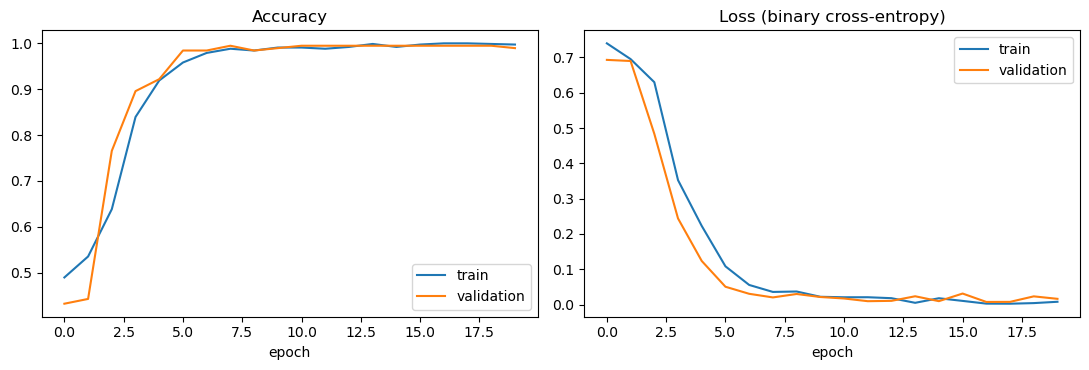

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='validation')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='validation')
ax[1].set_title('Loss (binary cross-entropy)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('results/training_curves.png', dpi=100); plt.show()

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

score = model.evaluate(X_test, y_test, verbose=0)
print(f'Test (Loss): {score[0]:.4f}')
print(f'Test (Accuracy): {score[1]*100:.2f}%')

y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Bloopsy', 'Zigrill']))

model.save('model_trained_data.h5', include_optimizer=False)
print('model_trained_data.h5 Saved')

Test (Loss): 0.0246
Test (Accuracy): 98.75%


[[120   2]
 [  1 117]]
              precision    recall  f1-score   support

     Bloopsy       0.99      0.98      0.99       122
     Zigrill       0.98      0.99      0.99       118

    accuracy                           0.99       240
   macro avg       0.99      0.99      0.99       240
weighted avg       0.99      0.99      0.99       240

model_trained_data.h5 Saved


**Honest note on this test score:** the test split comes from the *augmented* pool, so augmented copies of the same original drawing can land in both train and test. That makes this number optimistic. The real check is Step 4, on 12 drawings the model never saw in any form.